# Tuần 2 – Đặc trưng thống nhất · 4 baseline · Mô hình riêng **GA-DCR** · Phân cụm động K-means++ × GA · *Ưu tiên Recall và F2*
**Đề tài NCKH SV – ĐH Phenikaa:** Cảnh báo sớm sinh viên có nguy cơ học tập kém bằng AI · Dữ liệu: **OULAD** và **UCI 697**

| # | Yêu cầu tuần 2 | Phần |
|---|---|---|
| 1 | Chỉ số: **Recall và F2 là chính**, Precision là ràng buộc ổn định | §1 |
| 2 | Thống nhất bộ đặc trưng cho 2 bộ dữ liệu, bổ sung đặc trưng mới từ kết quả tuần 1 | §2–§3 |
| 3 | 4 baseline **khác bài báo tham khảo:** Logistic Regression, Decision Tree, Random Forest, XGBoost | §5 |
| 4 | **Phân cụm động:** K-means++ có GA tối ưu, sinh ra các mức cảnh báo theo dữ liệu và theo thời gian | §4 |
| 5 | **Mô hình riêng GA-DCR** đặt cạnh 4 baseline (tuần 2 chưa yêu cầu phải thắng) | §5–§6 |
| 6 | Điểm mới so với bài báo tham khảo (Wang, *Sci. Reports* 15:35122, 2025) | §7 |

> Đặt notebook trong cùng thư mục với `oulad/` và `uci_697/` (giống tuần 1). Thời gian chạy khoảng 3–5 phút. Kết quả được ghi vào `week2_outputs/`.

## §1. Chỉ số đánh giá: **Recall và F2 là chính, Precision là ràng buộc ổn định**
**Bản chất trong bài toán cảnh báo học vụ:**
- **Recall** = TP/(TP+FN): trong số SV *thực sự* sẽ trượt hoặc bỏ học, hệ thống **phát hiện được bao nhiêu**. Bỏ sót (FN) là sai lầm **không sửa lại được**, vì đến cuối kỳ mới biết thì đã quá muộn để can thiệp.
- **Precision** = TP/(TP+FP): trong danh sách đưa cho cố vấn, bao nhiêu SV **thực sự cần giúp**. Báo nhầm (FP) chỉ tốn một buổi gặp, nhưng báo nhầm quá nhiều sẽ khiến cố vấn quá tải và mất niềm tin vào hệ thống.
- **F2** = $5PR/(4P+R)$ coi **Recall nặng gấp đôi Precision**, đúng với cái giá không cân xứng giữa hai loại sai.

| Vai trò | Chỉ số |
|---|---|
| **Chỉ số chính** (chọn mô hình, chọn ngưỡng) | **Recall, F2** |
| **Ràng buộc ổn định** | Precision ≥ $P_{min}$, % SV bị cảnh báo ≤ $A_{max}$, độ lệch Precision giữa các fold nhỏ |
| Chỉ số bổ trợ | PR-AUC (chất lượng xếp hạng), Recall@Top-20% (theo năng lực cố vấn) |
| Chỉ để tham chiếu | F1, Accuracy, ROC-AUC (Accuracy **không** dùng vì dữ liệu lệch lớp) |

**Vì sao F2 phải có ràng buộc?** Với OULAD (tỷ lệ nguy cơ khoảng 44%), cách "cảnh báo **tất cả** SV" có Recall = 1 và đã đạt F2 khoảng 0,79, nhưng hoàn toàn vô dụng. Tối đa F2 tự do sẽ đẩy ngưỡng xuống rất thấp và báo động tới hơn 85% SV. Vì vậy ngưỡng vận hành được chọn theo bài toán:
$$\tau^*=\arg\max_{\tau} F_2(\tau)\quad\text{s.t.}\quad \text{Precision}(\tau)\ \ge\ P_{min}=\max\!\big(0{,}5;\ \bar y_{train}+0{,}15\big),\qquad \text{AlertRate}(\tau)\le A_{max}=50\%$$
- $P_{min}$: danh sách cảnh báo phải **trúng hơn hẳn chọn ngẫu nhiên** (lift ≥ 15 điểm %) và ít nhất 1 lần báo nhầm cho mỗi 1 lần báo đúng.
- $A_{max}$: không cảnh báo quá nửa số SV, giới hạn theo năng lực tư vấn.
- **Độ ổn định của Precision** được đo bằng độ lệch chuẩn giữa 5 fold OOF.

τ\* chọn trên **out-of-fold của tập train**, không nhìn tập test. Bảng kết quả có thêm dòng *"Cảnh báo tất cả"* để thấy mô hình vượt mức suy biến bao nhiêu. Tuần 2 chỉ đặt GA-DCR cạnh 4 baseline; việc cải thiện để thắng thuộc các tuần sau.

## §0. Cấu hình và nạp dữ liệu

In [1]:
%matplotlib inline
import os
os.environ["PYTHONWARNINGS"] = "ignore"          # tắt cảnh báo của các tiến trình con (joblib/loky)
import re, json, time, warnings, gc
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
                             roc_auc_score, average_precision_score, silhouette_score, confusion_matrix)
from sklearn.model_selection import StratifiedKFold, train_test_split
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 220)
try:
    from xgboost import XGBClassifier; HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("⚠ Chưa cài xgboost → dùng HistGradientBoosting thay thế (pip install xgboost để đúng yêu cầu)")

OULAD_DIR = None      # để None => tự dò; hoặc r"C:\...\oulad"
UCI697_FILE = None    # để None => tự dò; hoặc r"C:\...\uci_697\data.csv"
BASE = Path.cwd(); OUT = BASE / "week2_outputs"; FIG = OUT / "figures"; TAB = OUT / "tables"
for p in (FIG, TAB): p.mkdir(parents=True, exist_ok=True)
SEED = 42; rng_global = np.random.default_rng(SEED)

def _roots(): return [BASE, BASE.parent, BASE.parent.parent]
def find_oulad_dir():
    for root in _roots():
        for d in [root / "oulad"] + sorted(p for p in root.glob("*oulad*") if p.is_dir()):
            if d.is_dir():
                hit = next(d.rglob("studentInfo.csv"), None)
                if hit is not None: return hit.parent
    raise FileNotFoundError("Không tìm thấy studentInfo.csv – điền OULAD_DIR")
def find_uci697_file():
    for root in _roots():
        for d in [root / "uci_697"] + sorted(p for p in root.glob("*697*") if p.is_dir()):
            if d.is_dir():
                for f in sorted(d.rglob("*.csv")):
                    h = f.read_text(encoding="utf-8-sig", errors="ignore")[:4000]
                    if "Target" in h and "Curricular units" in h: return f
    raise FileNotFoundError("Không tìm thấy CSV UCI 697 – điền UCI697_FILE")
OULAD_DIR = Path(OULAD_DIR) if OULAD_DIR else find_oulad_dir()
UCI697_FILE = Path(UCI697_FILE) if UCI697_FILE else find_uci697_file()
print("OULAD:", OULAD_DIR, "\nUCI 697:", UCI697_FILE)

PAL = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100", magenta="#e87ba4",
           green="#008300", violet="#6250d6", red="#e34948")
INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
MODEL_COLORS = {"LogReg": PAL["blue"], "DecisionTree": PAL["orange"], "RandomForest": PAL["aqua"],
                "XGBoost": PAL["yellow"], "GA-DCR (đề xuất)": PAL["violet"], "(tham chiếu) Cảnh báo tất cả": MUTED}
LEVEL_COLORS = {"Xanh": "#1baf7a", "Vàng": "#eda100", "Cam": "#ec835a", "Đỏ": "#d03b3b"}
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False, "lines.linewidth": 2, "figure.dpi": 100, "savefig.dpi": 150,
    "savefig.bbox": "tight"})
def save_show(fig, name): fig.savefig(FIG / name); plt.show()
def save_tab(df, name, index=False): df.to_csv(TAB / name, index=index, encoding="utf-8-sig"); return df

OULAD: /home/claude/nb3/oulad 
UCI 697: /home/claude/nb3/uci_697/data.csv


In [2]:
t0 = time.time(); NA = ["?", ""]
O = {k: pd.read_csv(OULAD_DIR / f"{k}.csv", na_values=NA) for k in
     ["courses", "assessments", "vle", "studentInfo", "studentRegistration", "studentAssessment"]}
O["studentVle"] = pd.read_csv(OULAD_DIR / "studentVle.csv", dtype={"code_module": "category",
                  "code_presentation": "category", "id_student": "int32", "id_site": "int32", "date": "int16", "sum_click": "int32"})
head = UCI697_FILE.read_text(encoding="utf-8-sig", errors="ignore")[:4000]
uci = pd.read_csv(UCI697_FILE, sep=";" if head.count(";") > head.count(",") else ",", encoding="utf-8-sig")
uci.columns = [re.sub(r"\s+", " ", c).strip() for c in uci.columns]
uci = uci.rename(columns={"Nacionality": "Nationality"}); uci["Target"] = uci.Target.astype(str).str.strip()
print(f"Nạp xong {time.time()-t0:.0f}s | OULAD studentVle = {len(O['studentVle']):,} dòng | UCI 697 = {uci.shape}")

Nạp xong 4s | OULAD studentVle = 10,655,280 dòng | UCI 697 = (4424, 37)


---
## §2. Xây dựng đặc trưng (gồm đặc trưng mới rút ra từ kết quả tuần 1)
### 2.1 OULAD – đặc trưng tại mốc ngày t, chống rò rỉ dữ liệu
Tuần 1 cho thấy 3 điều:
1. Hành vi trên LMS **so với bạn cùng lớp** mạnh hơn số click tuyệt đối.
2. **Tín hiệu suy giảm gần đây** (lâu không đăng nhập, nhiều tuần không hoạt động) làm tăng nguy cơ.
3. **Kỷ luật nộp bài** (bỏ lỡ hạn, nộp sát hạn) là tín hiệu mạnh.

Vì vậy tuần 2 bổ sung các đặc trưng mới (★), nhất là nhóm *động/xu hướng*.

In [3]:
ENR = ["code_module", "code_presentation", "id_student"]; CRS = ["code_module", "code_presentation"]
EDU = {"No Formal quals": 0, "Lower Than A Level": 1, "A Level or Equivalent": 2, "HE Qualification": 3, "Post Graduate Qualification": 4}
IMD = {f"{i*10}-{i*10+10}%": i for i in range(10)} | {"10-20": 1}
AGE = {"0-35": 0, "35-55": 1, "55<=": 2}
base_o = O["studentInfo"].merge(O["studentRegistration"], on=ENR)
base_o["at_risk"] = base_o.final_result.isin(["Fail", "Withdrawn"]).astype(int)
base_o["year"] = base_o.code_presentation.str[:4].astype(int)
base_o["edu_ord"] = base_o.highest_education.map(EDU); base_o["imd_ord"] = base_o.imd_band.map(IMD)
base_o["age_ord"] = base_o.age_band.map(AGE)
base_o["gender_M"] = (base_o.gender == "M").astype(int); base_o["disability_Y"] = (base_o.disability == "Y").astype(int)

sv = O["studentVle"].merge(O["vle"][["id_site", "activity_type"]], on="id_site")
for k in CRS: sv[k] = sv[k].astype(str)
daily = sv.groupby(ENR + ["date", "activity_type"]).sum_click.sum().rename("clicks").reset_index()
del sv; gc.collect()
A = O["assessments"]; A = A[A.assessment_type != "Exam"]
SA = O["studentAssessment"].merge(A, on="id_assessment"); SA = SA[SA.is_banked == 0]

def oulad_features(t):
    X = base_o[base_o.date_unregistration.isna() | (base_o.date_unregistration >= t)].copy()
    dv = daily[daily.date < t]; g = dv.groupby(ENR)
    f = pd.DataFrame({"clicks_total": g.clicks.sum(), "active_days": g.date.nunique(), "last_day": g.date.max(),
                      "activity_diversity": g.activity_type.nunique(),                                   # ★
                      "clicks_prestart": dv[dv.date < 0].groupby(ENR).clicks.sum(),
                      "clk_forum": dv[dv.activity_type == "forumng"].groupby(ENR).clicks.sum(),
                      "clk_quiz": dv[dv.activity_type == "quiz"].groupby(ENR).clicks.sum()})
    rec = dv[dv.date >= t - 14].groupby(ENR)
    f["clicks_last14"] = rec.clicks.sum(); f["active_days_last14"] = rec.date.nunique()
    nw = max(1, int(np.ceil(t / 7)))
    wk = dv[dv.date >= 0].assign(w=lambda x: x.date // 7).groupby(ENR + ["w"]).clicks.sum().unstack(fill_value=0)
    wk = wk.reindex(columns=range(nw), fill_value=0)
    xs = np.arange(nw) - (nw - 1) / 2
    f = f.join(pd.DataFrame({
        "clicks_week_slope": (np.log1p(wk.values) @ xs / max(1e-9, xs @ xs)) if nw > 1 else 0.0,          # ★ xu hướng
        "weeks_inactive": (wk.values == 0).sum(1),                                                       # ★
        "engagement_cv": wk.std(1).values / (wk.mean(1).values + 1)}, index=wk.index))                     # ★ đều đặn
    X = X.merge(f.reset_index(), on=ENR, how="left")
    for c in ["clicks_total", "active_days", "activity_diversity", "clicks_prestart", "clk_forum", "clk_quiz",
              "clicks_last14", "active_days_last14", "clicks_week_slope", "engagement_cv"]:
        X[c] = X[c].fillna(0)
    X["weeks_inactive"] = X.weeks_inactive.fillna(nw)
    X["days_since_last_active"] = (t - X.last_day).fillna(t + 30)                                         # ★
    X["clicks_pct_in_course"] = X.groupby(CRS).clicks_total.rank(pct=True)                                 # ★ tương đối
    X["active_pct_in_course"] = X.groupby(CRS).active_days.rank(pct=True)                                  # ★
    X["recent_share"] = X.clicks_last14 / (X.clicks_total + 1)                                             # ★
    X["forum_share"] = X.clk_forum / (X.clicks_total + 1); X["quiz_share"] = X.clk_quiz / (X.clicks_total + 1)  # ★
    s = SA[SA.date_submitted < t]; gs = s.groupby(ENR); key = [s[k] for k in ENR]
    fa = pd.DataFrame({"n_submitted": gs.size(), "mean_score": gs.score.mean(), "min_score": gs.score.min(),
                       "weighted_score": (s.score * s.weight).groupby(key).sum() / s.weight.groupby(key).sum().replace(0, np.nan),
                       "mean_days_early": (s.date - s.date_submitted).groupby(key).mean(),                 # ★ kỷ luật
                       "n_fail_assess": (s.score < 40).groupby(key).sum()})
    X = X.merge(fa.reset_index(), on=ENR, how="left")
    due = A[A.date < t].groupby(CRS).size().rename("n_due").reset_index()
    sub = s[s.date < t].groupby(ENR).size().rename("n_sub_due").reset_index()
    X = X.merge(due, on=CRS, how="left").merge(sub, on=ENR, how="left")
    X[["n_due", "n_sub_due", "n_submitted", "n_fail_assess"]] = X[["n_due", "n_sub_due", "n_submitted", "n_fail_assess"]].fillna(0)
    X["n_missed"] = (X.n_due - X.n_sub_due).clip(lower=0)                                                  # ★
    X["submit_rate"] = np.where(X.n_due > 0, X.n_sub_due / X.n_due.replace(0, 1), 1.0)
    X["score_rel_course"] = X.mean_score - X.groupby(CRS).mean_score.transform("median")                  # ★
    return X.drop(columns=["last_day", "clk_forum", "clk_quiz", "n_sub_due", "n_due"])

OULAD_GROUPS = {
    "G1 Nền tảng cá nhân": ["gender_M", "age_ord", "disability_Y", "imd_ord", "edu_ord"],
    "G2 Học vụ/hành chính": ["num_of_prev_attempts", "studied_credits", "date_registration", "code_module"],
    "G3 Kết quả quá trình": ["mean_score", "min_score", "weighted_score", "n_fail_assess", "score_rel_course"],
    "G4 Mức độ tham gia": ["clicks_total", "active_days", "clicks_pct_in_course", "active_pct_in_course",
                               "clicks_prestart", "activity_diversity", "forum_share", "quiz_share"],
    "G5 Kỷ luật & tài chính": ["n_submitted", "n_missed", "submit_rate", "mean_days_early"],
    "G6 Động/xu hướng": ["clicks_last14", "active_days_last14", "recent_share", "clicks_week_slope",
                         "weeks_inactive", "days_since_last_active", "engagement_cv"],
}
X28 = oulad_features(28)
print("OULAD ngày 28:", X28.shape, "| tỷ lệ nguy cơ", round(X28.at_risk.mean(), 3))

OULAD ngày 28: (27553, 45) | tỷ lệ nguy cơ 0.442


### 2.2 UCI 697 – đặc trưng theo 3 mốc: **lúc nhập học → sau HK1 → sau HK2**
Từ tuần 1 rút ra:
- Tỷ lệ qua môn và **tình trạng tài chính** là tín hiệu mạnh nhất.
- Các biến vĩ mô không có tác dụng, nên **loại bỏ**.
- Nghề nghiệp của bố mẹ có quá nhiều mã và tác dụng yếu, nên **loại bỏ**.

In [4]:
U = uci.copy(); U["at_risk"] = (U.Target == "Dropout").astype(int)
for s, tag in [("1st", "1"), ("2nd", "2")]:
    cu = lambda k: U[f"Curricular units {s} sem ({k})"]
    U[f"enrolled_{tag}"] = cu("enrolled"); U[f"approved_{tag}"] = cu("approved"); U[f"grade_{tag}"] = cu("grade")
    U[f"pass_ratio_{tag}"] = np.where(cu("enrolled") > 0, cu("approved") / cu("enrolled").replace(0, 1), np.nan)      # ★
    U[f"eval_per_unit_{tag}"] = np.where(cu("enrolled") > 0, cu("evaluations") / cu("enrolled").replace(0, 1), np.nan) # ★
    U[f"no_eval_ratio_{tag}"] = np.where(cu("enrolled") > 0, cu("without evaluations") / cu("enrolled").replace(0, 1), np.nan)  # ★
    U[f"credited_share_{tag}"] = cu("credited") / (cu("credited") + cu("enrolled") + 1)                   # ★
U["financial_risk_index"] = U.Debtor + (1 - U["Tuition fees up to date"]) + (1 - U["Scholarship holder"])   # ★ 0–3
U["admission_gap"] = U["Admission grade"] - U["Previous qualification (grade)"]                          # ★
U["grade_delta"] = U.grade_2 - U.grade_1                                                                  # ★ động
U["pass_ratio_delta"] = U.pass_ratio_2 - U.pass_ratio_1                                                   # ★ động
U["approved_delta"] = U.approved_2 - U.approved_1                                                         # ★ động

UCI_CAT = ["Application mode", "Course", "Previous qualification", "Marital status",
           "Mother's qualification", "Father's qualification"]
UCI_GROUPS = {
    "G1 Nền tảng cá nhân": ["Gender", "Age at enrollment", "Marital status", "International", "Displaced",
                            "Educational special needs", "Mother's qualification", "Father's qualification"],
    "G2 Học vụ/hành chính": ["Application mode", "Application order", "Course", "Daytime/evening attendance",
                             "Previous qualification", "Previous qualification (grade)", "Admission grade", "admission_gap"],
    "G3 Kết quả quá trình": ["approved_1", "grade_1", "pass_ratio_1", "approved_2", "grade_2", "pass_ratio_2"],
    "G4 Mức độ tham gia": ["enrolled_1", "eval_per_unit_1", "credited_share_1", "enrolled_2", "eval_per_unit_2", "credited_share_2"],
    "G5 Kỷ luật & tài chính": ["no_eval_ratio_1", "no_eval_ratio_2", "Debtor", "Tuition fees up to date",
                               "Scholarship holder", "financial_risk_index"],
    "G6 Động/xu hướng": ["grade_delta", "pass_ratio_delta", "approved_delta"],
}
UCI_STAGE = {"Nhập học": lambda c: not re.search(r"_(1|2)$|delta", c),
             "Sau HK1": lambda c: not re.search(r"_2$|delta", c),
             "Sau HK2": lambda c: True}
DROPPED_UCI = ["Unemployment rate", "Inflation rate", "GDP", "Nationality", "Mother's occupation", "Father's occupation"]
print("UCI 697:", U.shape, "| tỷ lệ Dropout", round(U.at_risk.mean(), 3))

UCI 697: (4424, 57) | tỷ lệ Dropout 0.321


---
## §3. Thống nhất bộ đặc trưng cho 2 bộ dữ liệu
Cả hai bộ được quy về **cùng một khung 6 nhóm đặc trưng** (G1–G6), để mô hình và hệ thống cảnh báo dùng chung một cách diễn giải. Quy trình chọn lọc có 2 bước, chỉ thực hiện **trên tập train**:
1. **Lọc theo tri thức** từ tuần 1: bỏ biến vĩ mô, biến trùng nghĩa, biến có quá nhiều mã mà tác dụng yếu.
2. **Lọc tương quan:** cặp đặc trưng nào có |Spearman ρ| > 0,85 thì giữ đặc trưng có |ρ| với nhãn cao hơn. Ngưỡng 0,85 giống bài báo tham khảo, nhưng ở đây dùng Spearman vì nhiều biến lệch phân phối.

In [5]:
def corr_filter(df, feats, y, thr=0.85):
    num = [c for c in feats if pd.api.types.is_numeric_dtype(df[c])]
    cm = df[num].corr(method="spearman").abs()
    rel = df[num].corrwith(pd.Series(y, index=df.index), method="spearman").abs()
    drop, log = set(), []
    for i, a in enumerate(num):
        for b in num[i + 1:]:
            if a in drop or b in drop: continue
            if cm.loc[a, b] > thr:
                lose = a if rel[a] < rel[b] else b; keep = b if lose == a else a
                drop.add(lose); log.append((lose, keep, round(cm.loc[a, b], 3)))
    return [c for c in feats if c not in drop], log

# Chia dữ liệu: OULAD theo thời gian (2013 → 2014) và loại SV đã xuất hiện ở train khỏi test (tránh rò rỉ theo SV)
tr_o = X28[X28.year == 2013]; te_o = X28[(X28.year == 2014) & (~X28.id_student.isin(tr_o.id_student))]
print(f"OULAD: train 2013 = {len(tr_o):,} | test 2014 = {len(te_o):,} (đã loại {((X28.year==2014)&X28.id_student.isin(tr_o.id_student)).sum():,} lượt của SV có ở train)")
idx_tr_u, idx_te_u = train_test_split(U.index, test_size=0.2, stratify=U.at_risk, random_state=SEED)
print(f"UCI 697: train = {len(idx_tr_u):,} | test = {len(idx_te_u):,} (80/20 phân tầng)")

all_o = sum(OULAD_GROUPS.values(), [])
FEAT_O, drop_o = corr_filter(tr_o, all_o, tr_o.at_risk.values)
all_u = sum(UCI_GROUPS.values(), [])
FEAT_U, drop_u = {}, {}
for st, f in UCI_STAGE.items():   # lọc tương quan RIÊNG từng mốc: mốc sớm không được "mượn" đặc trưng của mốc sau
    FEAT_U[st], drop_u[st] = corr_filter(U.loc[idx_tr_u], [c for c in all_u if f(c)], U.loc[idx_tr_u, "at_risk"].values)
FEAT_U_ALL = FEAT_U["Sau HK2"]

rows = []
for g in OULAD_GROUPS:
    rows.append(dict(nhom=g, OULAD_ung_vien=len(OULAD_GROUPS[g]), OULAD_giu=sum(c in FEAT_O for c in OULAD_GROUPS[g]),
                     UCI_ung_vien=len(UCI_GROUPS[g]), UCI_nhap_hoc=sum(c in FEAT_U["Nhập học"] for c in UCI_GROUPS[g]),
                     UCI_sau_HK1=sum(c in FEAT_U["Sau HK1"] for c in UCI_GROUPS[g]), UCI_sau_HK2=sum(c in FEAT_U["Sau HK2"] for c in UCI_GROUPS[g]),
                     OULAD_dac_trung=", ".join(c for c in OULAD_GROUPS[g] if c in FEAT_O),
                     UCI_dac_trung_sau_HK2=", ".join(c for c in UCI_GROUPS[g] if c in FEAT_U_ALL)))
feat_table = pd.DataFrame(rows)
numcols = ["OULAD_ung_vien", "OULAD_giu", "UCI_ung_vien", "UCI_nhap_hoc", "UCI_sau_HK1", "UCI_sau_HK2"]
feat_table = feat_table[["nhom"] + numcols + ["OULAD_dac_trung", "UCI_dac_trung_sau_HK2"]]
feat_table.loc[len(feat_table)] = ["TỔNG", *feat_table[numcols].sum().values, "", ""]
save_tab(feat_table, "03_unified_feature_set.csv")
display(feat_table)
print("Loại do tương quan cao (bị loại, giữ lại, |ρ|):")
print("  OULAD :", drop_o); print("  UCI   :", drop_u)
print("  UCI loại theo tri thức tuần 1:", DROPPED_UCI)
print("OULAD dùng", len(FEAT_O), "đặc trưng |", {st: len(v) for st, v in FEAT_U.items()}, "← số đặc trưng UCI theo mốc")

OULAD: train 2013 = 11,818 | test 2014 = 14,269 (đã loại 1,466 lượt của SV có ở train)
UCI 697: train = 3,539 | test = 885 (80/20 phân tầng)


,nhom,OULAD_ung_vien,OULAD_giu,UCI_ung_vien,UCI_nhap_hoc,UCI_sau_HK1,UCI_sau_HK2,OULAD_dac_trung,UCI_dac_trung_sau_HK2
0,G1 Nền tảng cá nhân,5,5,8,8,8,8,"gender_M, age_ord, disability_Y, imd_ord, edu_ord","Gender, Age at enrollment, Marital status, Int..."
1,G2 Học vụ/hành chính,4,4,8,8,8,8,"num_of_prev_attempts, studied_credits, date_re...","Application mode, Application order, Course, D..."
2,G3 Kết quả quá trình,5,2,6,0,3,5,"n_fail_assess, score_rel_course","grade_1, pass_ratio_1, approved_2, grade_2, pa..."
3,G4 Mức độ tham gia,8,5,6,0,3,4,"active_pct_in_course, clicks_prestart, activit...","eval_per_unit_1, enrolled_2, eval_per_unit_2, ..."
4,G5 Kỷ luật & tài chính,4,3,6,4,5,6,"n_submitted, n_missed, mean_days_early","no_eval_ratio_1, no_eval_ratio_2, Debtor, Tuit..."
5,G6 Động/xu hướng,7,6,3,0,0,2,"active_days_last14, recent_share, clicks_week_...","grade_delta, pass_ratio_delta"
6,TỔNG,33,25,37,20,27,33,,


Loại do tương quan cao (bị loại, giữ lại, |ρ|):
  OULAD : [('min_score', 'mean_score', np.float64(0.975)), ('weighted_score', 'mean_score', np.float64(0.976)), ('mean_score', 'score_rel_course', np.float64(0.925)), ('clicks_total', 'active_days', np.float64(0.894)), ('active_days', 'active_pct_in_course', np.float64(0.882)), ('clicks_pct_in_course', 'active_pct_in_course', np.float64(0.889)), ('submit_rate', 'n_missed', np.float64(0.999)), ('clicks_last14', 'active_days_last14', np.float64(0.861))]
  UCI   : {'Nhập học': [], 'Sau HK1': [], 'Sau HK2': [('approved_1', 'approved_2', np.float64(0.887)), ('enrolled_1', 'enrolled_2', np.float64(0.96)), ('credited_share_1', 'credited_share_2', np.float64(0.91)), ('approved_delta', 'pass_ratio_delta', np.float64(0.858))]}
  UCI loại theo tri thức tuần 1: ['Unemployment rate', 'Inflation rate', 'GDP', 'Nationality', "Mother's occupation", "Father's occupation"]
OULAD dùng 25 đặc trưng | {'Nhập học': 20, 'Sau HK1': 27, 'Sau HK2': 33} ← số đặc tr

---
## §4. Phân cụm động: **GA-KMeans++** sinh ra các mức cảnh báo
### 4.1 Vì sao K-means++ thông thường chưa đủ?
K-means++ chỉ cải tiến bước **khởi tạo tâm**. Nó vẫn có 3 hạn chế: (i) số cụm *k* phải chọn bằng tay; (ii) mọi đặc trưng có trọng số như nhau; (iii) cụm được tạo ra **không quan tâm đến rủi ro**, nên không tự trở thành "mức cảnh báo".

### 4.2 GA-DKC (*GA-optimized Dynamic K-means++ Clustering*) – thuật toán của nhóm
Dùng **Giải thuật di truyền (GA)** để tối ưu đồng thời số cụm và trọng số đặc trưng. **Nhiễm sắc thể** là $\theta = (k,\; w_1,\dots,w_d)$, với $k\in\{3..8\}$ (tối thiểu 3 mức để cảnh báo có ý nghĩa phân tầng) và $w_j\in[0.05,1]$. K-means++ chạy trong không gian có trọng số, với khoảng cách
$$d_w(x, c) = \sum_{j=1}^{d} w_j\,(z_j - c_j)^2 .$$

**Hàm thích nghi** cân bằng giữa *cấu trúc cụm* và *khả năng phân tách rủi ro*:
$$\text{Fit}(\theta) = \lambda\cdot \text{Silhouette}_w + (1-\lambda)\cdot \eta^2_{risk} - \gamma\,k - \text{Penalty}_{min}$$
Trong đó:
- dữ liệu được biến đổi phân vị → chuẩn trước khi phân cụm, để ngoại lai không lấn át khoảng cách;
- $\eta^2_{risk} = \dfrac{\sum_k n_k(\bar y_k - \bar y)^2}{\sum_i (y_i-\bar y)^2}$ là tỷ lệ phương sai của nhãn nguy cơ được các cụm giải thích, tính **chỉ trên train**;
- $\lambda = 0{,}35$ (ưu tiên phân tách rủi ro) và $\gamma = 0{,}003$ (thưởng cho mô hình gọn, ít cụm);
- $\text{Penalty}_{min} = 1$ nếu có cụm nhỏ hơn 3% dữ liệu.

**Sinh mức cảnh báo:**
- Sắp xếp cụm theo **xác suất rủi ro hậu nghiệm có làm trơn Bayes** $\pi_k = \dfrac{n_k^{+} + m\,\bar y}{n_k + m}$ (với $m = 20$).
- Ánh xạ sang 4 màu: **Xanh** $\pi<0{,}25$, **Vàng** $<0{,}5$, **Cam** $<0{,}75$, **Đỏ** $\ge0{,}75$.

**"Động"** thể hiện ở 2 tầng:
1. **Tối ưu động:** GA tự chọn *k* và trọng số theo dữ liệu, không đặt cố định.
2. **Động theo thời gian:** chạy lại ở từng mốc (OULAD: ngày 14 → 28 → 56 → 84; UCI: nhập học → HK1 → HK2). Tâm cụm được **khởi tạo ấm** (warm-start) từ mốc trước khi *k* không đổi. Từ đó theo dõi **SV chuyển mức cảnh báo** qua thời gian.

Toàn bộ GA, tâm cụm và $\pi_k$ chỉ học trên **train**. Tập test được gán vào cụm gần nhất.

In [6]:
class GADynamicKMeans:
    def __init__(self, k_range=(3, 8), pop=18, gens=15, lam=0.35, gamma=0.003, sample=3000, m_prior=20, seed=SEED):
        self.k_range, self.pop, self.gens, self.lam, self.gamma = k_range, pop, gens, lam, gamma
        self.sample, self.m, self.rng = sample, m_prior, np.random.default_rng(seed)
    def _fitness(self, Zs, ys, k, w, Zsil, sil_idx):
        Zw = Zs * np.sqrt(w)
        km = KMeans(k, init="k-means++", n_init=2, max_iter=150, random_state=int(self.rng.integers(1e6))).fit(Zw)
        lab = km.labels_; share = np.bincount(lab, minlength=k) / len(lab)
        sil = silhouette_score(Zw[sil_idx], lab[sil_idx]) if len(np.unique(lab[sil_idx])) > 1 else -1
        yb = ys.mean(); ssb = sum((lab == j).sum() * (ys[lab == j].mean() - yb) ** 2 for j in range(k) if (lab == j).any())
        eta2 = ssb / max(1e-12, ((ys - yb) ** 2).sum())
        pen = 1.0 if share.min() < 0.03 else 0.0
        return self.lam * sil + (1 - self.lam) * eta2 - self.gamma * k - pen, sil, eta2
    def fit(self, Z, y, prev=None):
        n, d = Z.shape; self.d = d
        idx = self.rng.choice(n, min(self.sample, n), replace=False); Zs, ys = Z[idx], y[idx]
        sil_idx = self.rng.choice(len(idx), min(1500, len(idx)), replace=False)
        P = [(int(self.rng.integers(self.k_range[0], self.k_range[1] + 1)), self.rng.uniform(0.2, 1, d)) for _ in range(self.pop)]
        if prev is not None: P[0] = (prev.k, prev.w.copy())                      # khởi tạo ấm từ mốc trước
        evals = [self._fitness(Zs, ys, k, w, Zs, sil_idx) for k, w in P]
        self.history = []
        for g in range(self.gens):
            fit = np.array([e[0] for e in evals]); self.history.append((fit.max(), fit.mean()))
            order = np.argsort(-fit); newP = [P[order[0]], P[order[1]]]; newE = [evals[order[0]], evals[order[1]]]  # elitism
            while len(newP) < self.pop:
                def tour():
                    c = self.rng.choice(self.pop, 3, replace=False); return P[c[np.argmax(fit[c])]]
                (k1, w1), (k2, w2) = tour(), tour()
                mask = self.rng.random(d) < 0.5; w = np.where(mask, w1, w2)                       # lai ghép đồng nhất
                k = k1 if self.rng.random() < 0.5 else k2
                mut = self.rng.random(d) < 0.3; w = np.clip(w + mut * self.rng.normal(0, 0.15, d), 0.05, 1)  # đột biến
                if self.rng.random() < 0.25: k = int(np.clip(k + self.rng.choice([-1, 1]), *self.k_range))
                newP.append((k, w)); newE.append(self._fitness(Zs, ys, k, w, Zs, sil_idx))
            P, evals = newP, newE
        fit = np.array([e[0] for e in evals]); best = int(np.argmax(fit))
        self.k, self.w = P[best]; self.best_fit, self.sil, self.eta2 = evals[best]
        self.history.append((fit.max(), fit.mean()))
        Zw = Z * np.sqrt(self.w)
        init = "k-means++"
        if prev is not None and prev.k == self.k:
            init = prev.centers_w_unsorted * np.sqrt(self.w) / np.sqrt(prev.w)          # warm-start tâm cụm
        km = KMeans(self.k, init=init, n_init=1 if not isinstance(init, str) else 5, random_state=SEED).fit(Zw)
        lab = km.labels_; self.centers_w_unsorted = km.cluster_centers_
        n_k = np.bincount(lab, minlength=self.k); pos = np.bincount(lab, weights=y, minlength=self.k)
        pi = (pos + self.m * y.mean()) / (n_k + self.m)
        self.order = np.argsort(pi); self.pi = pi[self.order]                           # cụm 0 = rủi ro thấp nhất
        self.centers_w = km.cluster_centers_[self.order]
        d2 = ((Zw[:, None, :] - self.centers_w[None]) ** 2).sum(-1); self.T = np.median(d2.min(1)) + 1e-9
        return self
    def _d2(self, Z):
        Zw = Z * np.sqrt(self.w); return ((Zw[:, None, :] - self.centers_w[None]) ** 2).sum(-1)
    def predict(self, Z): return self._d2(Z).argmin(1)
    def soft(self, Z):
        a = -self._d2(Z) / self.T; a -= a.max(1, keepdims=True); e = np.exp(a); return e / e.sum(1, keepdims=True)
    def level_names(self):
        return ["Xanh" if p < .25 else "Vàng" if p < .5 else "Cam" if p < .75 else "Đỏ" for p in self.pi]

def prep_cluster_matrix(df_tr, df_te, feats):
    # Ma trận cho phân cụm: điền khuyết bằng median train + log cho biến đếm lệch + chuẩn hóa (fit train)
    # Biến đổi phân vị → phân phối chuẩn (fit trên train): chống ngoại lai lấn át khoảng cách K-means
    from sklearn.preprocessing import QuantileTransformer
    tr, te = df_tr[feats].astype(float).copy(), df_te[feats].astype(float).copy()
    med = tr.median(); tr, te = tr.fillna(med), te.fillna(med)
    qt = QuantileTransformer(n_quantiles=200, output_distribution="normal", subsample=100_000, random_state=SEED).fit(tr)
    return np.clip(qt.transform(tr), -3, 3), np.clip(qt.transform(te), -3, 3)

### 4.3 OULAD – phân cụm động qua 4 mốc thời gian (ngày 14 → 28 → 56 → 84)

In [7]:
CL_O = [c for c in ["clicks_pct_in_course", "active_pct_in_course", "clicks_last14", "days_since_last_active",
                    "weeks_inactive", "clicks_week_slope", "activity_diversity", "mean_score", "n_missed",
                    "mean_days_early", "submit_rate"] if c in FEAT_O or c in ["mean_score"]]
print("Đặc trưng dùng phân cụm OULAD:", CL_O)
dyn_o, prev, levels_o, feats_by_t = [], None, {}, {}
t_start = time.time()
for t in [14, 28, 56, 84]:
    Xt = X28 if t == 28 else oulad_features(t)
    tr = Xt[Xt.year == 2013]; te = Xt[(Xt.year == 2014) & (~Xt.id_student.isin(tr_o.id_student))]
    Ztr, Zte = prep_cluster_matrix(tr, te, CL_O)
    ga = GADynamicKMeans().fit(Ztr, tr.at_risk.values, prev=prev)
    lab_tr, lab_te = ga.predict(Ztr), ga.predict(Zte); names = ga.level_names()
    for j in range(ga.k):
        dyn_o.append(dict(ngay=t, k=ga.k, cum=j, muc=names[j], pi_train=round(ga.pi[j], 3),
                          ty_le_train=round((lab_tr == j).mean(), 3),
                          ty_le_nguy_co_test=round(te.at_risk.values[lab_te == j].mean(), 3) if (lab_te == j).any() else np.nan,
                          n_test=int((lab_te == j).sum()), silhouette=round(ga.sil, 3), eta2=round(ga.eta2, 3)))
    levels_o[t] = pd.Series(np.array(names)[lab_te], index=pd.MultiIndex.from_frame(te[ENR]))
    feats_by_t[t] = (ga, te, Zte)
    if t == 28: ga28_o = ga
    prev = ga
    print(f"ngày {t:>2}: k*={ga.k} | silhouette={ga.sil:.3f} | η²={ga.eta2:.3f} | mức={names} | {time.time()-t_start:.0f}s")
dyn_o = save_tab(pd.DataFrame(dyn_o), "04_oulad_dynamic_clusters.csv"); dyn_o

Đặc trưng dùng phân cụm OULAD: ['active_pct_in_course', 'days_since_last_active', 'weeks_inactive', 'clicks_week_slope', 'activity_diversity', 'mean_score', 'n_missed', 'mean_days_early']


ngày 14: k*=4 | silhouette=0.678 | η²=0.068 | mức=['Vàng', 'Vàng', 'Cam', 'Cam'] | 9s


ngày 28: k*=5 | silhouette=0.709 | η²=0.142 | mức=['Vàng', 'Vàng', 'Cam', 'Đỏ', 'Đỏ'] | 18s


ngày 56: k*=4 | silhouette=0.735 | η²=0.119 | mức=['Vàng', 'Vàng', 'Vàng', 'Cam'] | 28s


ngày 84: k*=3 | silhouette=0.715 | η²=0.240 | mức=['Xanh', 'Vàng', 'Đỏ'] | 40s


,ngay,k,cum,muc,pi_train,ty_le_train,ty_le_nguy_co_test,n_test,silhouette,eta2
0,14,4,0,Vàng,0.324,0.324,0.317,4189,0.678,0.068
1,14,4,1,Vàng,0.433,0.384,0.402,6190,0.678,0.068
2,14,4,2,Cam,0.580,0.184,0.547,2883,0.678,0.068
3,14,4,3,Cam,0.726,0.109,0.703,1255,0.678,0.068
4,28,5,0,Vàng,0.302,0.325,0.280,4264,0.709,0.142
5,28,5,1,Vàng,0.373,0.306,0.358,4574,0.709,0.142
6,28,5,2,Cam,0.504,0.246,0.505,4192,0.709,0.142
7,28,5,3,Đỏ,0.754,0.030,0.748,294,0.709,0.142
8,28,5,4,Đỏ,0.901,0.094,0.911,945,0.709,0.142
9,56,4,0,Vàng,0.259,0.351,0.224,5556,0.735,0.119


In [8]:
# Trọng số đặc trưng GA học được và hồ sơ cụm (ngày 28)
ga = ga28_o
wdf = pd.DataFrame({"dac_trung": CL_O, "trong_so_GA": ga.w.round(3)}).sort_values("trong_so_GA", ascending=False)
te28 = feats_by_t[28][1]; lab = ga.predict(feats_by_t[28][2])
prof = te28[CL_O].assign(cum=lab).groupby("cum").median().T
prof.columns = [f"C{j} {ga.level_names()[j]} (π={ga.pi[j]:.2f})" for j in prof.columns]
save_tab(prof.reset_index(names="dac_trung"), "04_oulad_cluster_profile_day28.csv")
display(wdf.T); display(prof.round(2))

,1,6,2,4,3,0,5,7
dac_trung,days_since_last_active,n_missed,weeks_inactive,activity_diversity,clicks_week_slope,active_pct_in_course,mean_score,mean_days_early
trong_so_GA,1.0,1.0,0.818,0.052,0.05,0.05,0.05,0.05


,C0 Vàng (π=0.30),C1 Vàng (π=0.37),C2 Cam (π=0.50),C3 Đỏ (π=0.75),C4 Đỏ (π=0.90)
active_pct_in_course,0.75,0.60,0.26,0.39,0.08
days_since_last_active,1.00,3.00,9.00,2.00,16.00
weeks_inactive,0.00,0.00,1.00,0.00,3.00
clicks_week_slope,0.01,-0.12,-0.07,-0.02,0.00
activity_diversity,8.00,7.00,5.00,8.00,4.00
mean_score,80.50,78.00,74.00,82.00,67.50
n_missed,0.00,0.00,0.00,1.00,1.00
mean_days_early,1.00,1.00,1.00,218.00,217.50


In [9]:
# Mức cảnh báo theo thời gian & chuyển mức của từng SV (tập test)
order_lv = ["Xanh", "Vàng", "Cam", "Đỏ"]
a, b = levels_o[28], levels_o[56]; j = pd.concat([a.rename("t28"), b.rename("t56")], axis=1, join="inner")
tm = pd.crosstab(j.t28, j.t56, normalize="index").reindex(index=order_lv, columns=order_lv).fillna(0)
print("Ma trận chuyển mức cảnh báo ngày 28 → 56 (tỷ lệ theo hàng):"); display(tm.round(2))
up = (j.t56.map(order_lv.index) > j.t28.map(order_lv.index)).mean(); dn = (j.t56.map(order_lv.index) < j.t28.map(order_lv.index)).mean()
print(f"Từ ngày 28 → 56: {up:.1%} SV tăng mức cảnh báo, {dn:.1%} giảm mức, {1-up-dn:.1%} giữ nguyên")
risk_by_level = pd.concat([pd.DataFrame({"muc": levels_o[t].values, "at_risk": feats_by_t[t][1].at_risk.values, "ngay": t})
                           for t in levels_o])
rbl = risk_by_level.groupby(["ngay", "muc"]).at_risk.agg(["mean", "size"]).unstack(0)
save_tab(rbl.round(3).reset_index(), "04_oulad_risk_by_level.csv"); print("Tỷ lệ nguy cơ THẬT theo mức (test):"); display(rbl["mean"].reindex(order_lv).round(3))

Ma trận chuyển mức cảnh báo ngày 28 → 56 (tỷ lệ theo hàng):


t56,Xanh,Vàng,Cam,Đỏ
t28,,,,
Xanh,0.0,0.00,0.00,0.0
Vàng,0.0,0.94,0.06,0.0
Cam,0.0,0.81,0.19,0.0
Đỏ,0.0,0.19,0.81,0.0


Từ ngày 28 → 56: 3.7% SV tăng mức cảnh báo, 31.8% giảm mức, 64.5% giữ nguyên
Tỷ lệ nguy cơ THẬT theo mức (test):


ngay,14,28,56,84
muc,,,,
Xanh,NaN,NaN,NaN,0.170
Vàng,0.368,0.320,0.321,0.328
Cam,0.594,0.505,0.828,NaN
Đỏ,NaN,0.872,NaN,0.716


### 4.4 UCI 697 – phân cụm động qua 3 mốc (nhập học → HK1 → HK2)

In [10]:
CL_U = {"Nhập học": ["Age at enrollment", "Admission grade", "Previous qualification (grade)", "financial_risk_index",
                     "Tuition fees up to date", "Scholarship holder", "Debtor", "Displaced", "Application order"],
        "Sau HK1": ["pass_ratio_1", "grade_1", "eval_per_unit_1", "no_eval_ratio_1", "enrolled_1"],
        "Sau HK2": ["pass_ratio_2", "grade_2", "grade_delta", "pass_ratio_delta"]}
dyn_u, prev, levels_u, cols = [], None, {}, []
trU, teU = U.loc[idx_tr_u], U.loc[idx_te_u]
for st in ["Nhập học", "Sau HK1", "Sau HK2"]:
    cols = cols + [c for c in CL_U[st] if c in U.columns]
    Ztr, Zte = prep_cluster_matrix(trU, teU, cols)
    ga = GADynamicKMeans(sample=3000).fit(Ztr, trU.at_risk.values, prev=prev if prev is not None and prev.d == len(cols) else None)
    lab_te = ga.predict(Zte); names = ga.level_names()
    for j in range(ga.k):
        dyn_u.append(dict(moc=st, k=ga.k, cum=j, muc=names[j], pi_train=round(ga.pi[j], 3),
                          ty_le_nguy_co_test=round(teU.at_risk.values[lab_te == j].mean(), 3) if (lab_te == j).any() else np.nan,
                          n_test=int((lab_te == j).sum()), silhouette=round(ga.sil, 3), eta2=round(ga.eta2, 3)))
    levels_u[st] = pd.Series(np.array(names)[lab_te], index=teU.index); prev = ga
    if st == "Sau HK1": ga_hk1_u = ga
    print(f"{st:<9}: {len(cols)} đặc trưng | k*={ga.k} | silhouette={ga.sil:.3f} | η²={ga.eta2:.3f} | mức={names}")
dyn_u = save_tab(pd.DataFrame(dyn_u), "04_uci697_dynamic_clusters.csv"); display(dyn_u)
jj = pd.concat([levels_u["Nhập học"].rename("a"), levels_u["Sau HK1"].rename("b")], axis=1)
print("Chuyển mức Nhập học → Sau HK1 (tỷ lệ theo hàng):"); display(pd.crosstab(jj.a, jj.b, normalize="index").reindex(index=order_lv, columns=order_lv).round(2))

Nhập học : 9 đặc trưng | k*=7 | silhouette=0.789 | η²=0.231 | mức=['Xanh', 'Xanh', 'Vàng', 'Vàng', 'Vàng', 'Đỏ', 'Đỏ']


Sau HK1  : 14 đặc trưng | k*=8 | silhouette=0.379 | η²=0.407 | mức=['Xanh', 'Xanh', 'Xanh', 'Xanh', 'Vàng', 'Vàng', 'Đỏ', 'Đỏ']


Sau HK2  : 18 đặc trưng | k*=6 | silhouette=0.363 | η²=0.432 | mức=['Xanh', 'Xanh', 'Xanh', 'Xanh', 'Đỏ', 'Đỏ']


,moc,k,cum,muc,pi_train,ty_le_nguy_co_test,n_test,silhouette,eta2
0,Nhập học,7,0,Xanh,0.098,0.070,71,0.789,0.231
1,Nhập học,7,1,Xanh,0.107,0.106,132,0.789,0.231
2,Nhập học,7,2,Vàng,0.252,0.268,298,0.789,0.231
3,Nhập học,7,3,Vàng,0.345,0.319,226,0.789,0.231
4,Nhập học,7,4,Vàng,0.380,0.341,44,0.789,0.231
5,Nhập học,7,5,Đỏ,0.801,0.897,68,0.789,0.231
6,Nhập học,7,6,Đỏ,0.838,0.804,46,0.789,0.231
7,Sau HK1,8,0,Xanh,0.084,0.065,77,0.379,0.407
8,Sau HK1,8,1,Xanh,0.096,0.061,82,0.379,0.407
9,Sau HK1,8,2,Xanh,0.109,0.056,125,0.379,0.407


Chuyển mức Nhập học → Sau HK1 (tỷ lệ theo hàng):


b,Xanh,Vàng,Cam,Đỏ
a,,,,
Xanh,1.00,0.00,NaN,0.00
Vàng,0.38,0.62,NaN,0.00
Cam,NaN,NaN,NaN,NaN
Đỏ,0.06,0.00,NaN,0.94


---
## §5. Mô hình riêng **GA-DCR** và 4 baseline
### 5.1 GA-DCR (*GA-optimized Dynamic Cluster-Risk model*)
GA-DCR gồm 4 bước. Kết quả phân cụm động ở §4 trở thành **tri thức rủi ro theo nhóm**, được đưa vào bộ phân loại có giám sát:

1. **Phân cụm động (GA-DKC):** cho ra $k^*$, trọng số $w$, tâm cụm $c_k$ và rủi ro cụm $\pi_k$ (§4).
2. **Thành viên mềm** của mỗi SV với từng cụm:
   $$s_k(x)=\frac{\exp\!\big(-d_w(x,c_k)/T\big)}{\sum_{j}\exp\!\big(-d_w(x,c_j)/T\big)}$$
   Từ đó tính **rủi ro tiên nghiệm theo cụm** $\;\rho(x)=\sum_k s_k(x)\,\pi_k$. Ở đây $\pi_k$ được tính **out-of-fold** để tránh rò rỉ nhãn.
3. **Bộ học có tăng cường cụm:** XGBoost nhạy chi phí (`scale_pos_weight` $= n^-/n^+$, phạt bỏ sót nặng hơn) huấn luyện trên $[\,x \,\|\, s(x) \,\|\, \rho(x)\,]$, cho ra xác suất $p(x)$.
4. **Hợp nhất và chọn ngưỡng hướng Recall:**
   $$R(x)=\alpha\,p(x)+(1-\alpha)\,\rho(x),\qquad (\alpha^*,\tau^*)=\arg\max_{\alpha,\tau} F_2 \ \ \text{s.t. } P\ge P_{min},\ \text{AlertRate}\le A_{max}\ \ \text{(trên OOF train)}$$
   SV được **cảnh báo** khi $R(x)\ge\tau^*$. **Mức cảnh báo** (Xanh/Vàng/Cam/Đỏ) cho biết thứ tự ưu tiên tư vấn: Đỏ trước, sau đó Cam, rồi Vàng.

### 5.2 Bốn baseline (khác bài báo tham khảo)
Logistic Regression · Decision Tree · Random Forest · XGBoost. Cả 4 dùng chung đặc trưng (§3), đều được cân bằng lớp, và **dùng cùng quy tắc chọn ngưỡng** như GA-DCR để so sánh công bằng. Ngưỡng 0,5 (như bài báo) chỉ báo cáo để tham chiếu.

In [11]:
def make_baselines(pw):
    ms = {"LogReg": LogisticRegression(max_iter=3000, C=0.5, class_weight="balanced"),
          "DecisionTree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=30, class_weight="balanced", random_state=SEED),
          "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)}
    ms["XGBoost"] = (XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=.8, colsample_bytree=.8,
                                   scale_pos_weight=pw, eval_metric="logloss", n_jobs=-1, random_state=SEED) if HAS_XGB else
                     HistGradientBoostingClassifier(max_iter=400, learning_rate=.05, class_weight="balanced", random_state=SEED))
    return ms

def make_pipe(model, num, cat, scale):
    nst = [("imp", SimpleImputer(strategy="median", add_indicator=True))] + ([("sc", StandardScaler())] if scale else [])
    tr = [("num", Pipeline(nst), num)]
    if cat: tr.append(("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="NA")),
                                        ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=False))]), cat))
    return Pipeline([("pre", ColumnTransformer(tr)), ("clf", model)])

def metrics(y, p, thr):
    yh = (p >= thr).astype(int); k = max(1, int(round(.2 * len(p)))); top = np.argsort(-p)[:k]
    return dict(threshold=thr, recall=recall_score(y, yh), f2=fbeta_score(y, yh, beta=2),
                precision=precision_score(y, yh, zero_division=0), alert_rate=yh.mean(), f1=f1_score(y, yh),
                pr_auc=average_precision_score(y, p), recall_top20=y[top].sum() / y.sum(),
                roc_auc=roc_auc_score(y, p) if len(np.unique(p)) > 1 else .5, accuracy=accuracy_score(y, yh))

A_MAX = 0.50
def constraints(y_train):
    return dict(p_min=max(0.50, y_train.mean() + 0.15), a_max=A_MAX)

def select_threshold(y, p, folds, p_min, a_max):
    # τ* = argmax F2  s.t. Precision ≥ p_min, AlertRate ≤ a_max  (trên OOF train) + đo độ ổn định Precision giữa các fold
    grid = np.arange(.05, .96, .01); best_f, best_t, feasible = -1, .5, True
    for t in grid:
        yh = (p >= t).astype(int)
        if yh.sum() == 0 or yh.mean() > a_max or precision_score(y, yh, zero_division=0) < p_min: continue
        f = fbeta_score(y, yh, beta=2)
        if f > best_f: best_f, best_t = f, t
    if best_f < 0:   # không ngưỡng nào thỏa → chọn ngưỡng có Precision cao nhất trong giới hạn cảnh báo
        feasible = False
        cand = [(precision_score(y, (p >= t).astype(int), zero_division=0), t) for t in grid if (p >= t).mean() <= a_max and (p >= t).sum() > 0]
        best_t = max(cand)[1] if cand else .5
    yh = (p >= best_t).astype(int)
    pf = [precision_score(y[b], yh[b], zero_division=0) for b in folds]; rf = [recall_score(y[b], yh[b]) for b in folds]
    return best_t, dict(oof_recall=recall_score(y, yh), oof_precision=precision_score(y, yh, zero_division=0),
                        oof_f2=fbeta_score(y, yh, beta=2), prec_fold_sd=float(np.std(pf)), rec_fold_sd=float(np.std(rf)),
                        dat_rang_buoc=feasible)

def split_cols(df, feats, cat_list):
    cat = [c for c in feats if c in cat_list or df[c].dtype == object]; return [c for c in feats if c not in cat], cat

In [12]:
class GADCR:
    # GA-optimized Dynamic Cluster-Risk model (mô hình đề xuất của nhóm)
    def __init__(self, cl_feats, num, cat, alphas=np.arange(.5, 1.01, .1)):
        self.cl, self.num, self.cat, self.alphas = cl_feats, num, cat, alphas
    def _learner(self, pw): return make_baselines(pw)["XGBoost"]
    def _cluster_feats(self, Z, pi):
        s = self.ga.soft(Z); return s, s @ pi
    def _aug(self, df, s, rho):
        A = df[self.num + self.cat].copy()
        for j in range(s.shape[1]): A[f"s_{j}"] = s[:, j]
        A["rho_cluster"] = rho; return A
    def _pi(self, lab, y, K, m=20):
        n = np.bincount(lab, minlength=K); pos = np.bincount(lab, weights=y, minlength=K); return (pos + m * y.mean()) / (n + m)
    def fit(self, tr, y, splits, cons, ga=None):
        self.Ztr, _ = prep_cluster_matrix(tr, tr.iloc[:2], self.cl); self._tr_ref = tr
        self.ga = ga if ga is not None else GADynamicKMeans().fit(self.Ztr, y)
        lab = self.ga.predict(self.Ztr); K = self.ga.k; pw = (y == 0).sum() / max(1, (y == 1).sum())
        anum = self.num + [f"s_{j}" for j in range(K)] + ["rho_cluster"]
        oof_p, oof_rho = np.zeros(len(y)), np.zeros(len(y))
        for a, b in splits:
            s, rho = self._cluster_feats(self.Ztr, self._pi(lab[a], y[a], K))
            m = make_pipe(self._learner(pw), anum, self.cat, scale=False).fit(self._aug(tr.iloc[a], s[a], rho[a]), y[a])
            oof_p[b] = m.predict_proba(self._aug(tr.iloc[b], s[b], rho[b]))[:, 1]; oof_rho[b] = rho[b]
        folds = [b for _, b in splits]; best = None
        for al in self.alphas:
            R = al * oof_p + (1 - al) * oof_rho; t, info = select_threshold(y, R, folds, **cons)
            score = info["oof_f2"] + (0 if info["dat_rang_buoc"] else -1)
            if best is None or score > best[0]: best = (score, al, t, info)
        _, self.alpha, self.tau, self.info = best
        self.pi_full = self._pi(lab, y, K); s, rho = self._cluster_feats(self.Ztr, self.pi_full)
        self.model = make_pipe(self._learner(pw), anum, self.cat, scale=False).fit(self._aug(tr, s, rho), y)
        return self
    def predict_proba(self, te):
        _, Zte = prep_cluster_matrix(self._tr_ref, te, self.cl); s, rho = self._cluster_feats(Zte, self.pi_full)
        p = self.model.predict_proba(self._aug(te, s, rho))[:, 1]
        self.last_level = np.array(self.ga.level_names())[self.ga.predict(Zte)]
        return self.alpha * p + (1 - self.alpha) * rho

def run_experiment(name, tr, te, feats, cat_list, cl_feats, ga=None):
    num, cat = split_cols(tr, feats, cat_list)
    for c in cat: tr[c], te[c] = tr[c].astype(str), te[c].astype(str)
    ytr, yte = tr.at_risk.values, te.at_risk.values; pw = (ytr == 0).sum() / (ytr == 1).sum()
    cons = constraints(ytr); splits = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(tr, ytr))
    folds = [b for _, b in splits]
    print(f"  Ràng buộc: Precision ≥ {cons['p_min']:.2f} | % cảnh báo ≤ {cons['a_max']:.0%} | tỷ lệ nguy cơ train = {ytr.mean():.3f}, test = {yte.mean():.3f}")
    rows, probs = [], {}
    for mname in make_baselines(pw):
        oof = np.zeros(len(ytr))
        for a, b in splits:
            m = make_pipe(make_baselines(pw)[mname], num, cat, scale=(mname == "LogReg")).fit(tr.iloc[a][num + cat], ytr[a])
            oof[b] = m.predict_proba(tr.iloc[b][num + cat])[:, 1]
        tau, info = select_threshold(ytr, oof, folds, **cons)
        m = make_pipe(make_baselines(pw)[mname], num, cat, scale=(mname == "LogReg")).fit(tr[num + cat], ytr)
        p = m.predict_proba(te[num + cat])[:, 1]; probs[mname] = p
        rows.append(dict(dataset=name, model=mname, nguong="vận hành (F2 có ràng buộc)", **metrics(yte, p, tau), **info, p_min=cons["p_min"]))
        rows.append(dict(dataset=name, model=mname, nguong="0,5 (tham chiếu)", **metrics(yte, p, .5)))
        print(f"  {mname:<13} τ*={tau:.2f} | OOF: R={info['oof_recall']:.3f} P={info['oof_precision']:.3f}±{info['prec_fold_sd']:.3f}")
    g = GADCR(cl_feats, num, cat).fit(tr, ytr, splits, cons, ga=ga); p = g.predict_proba(te); probs["GA-DCR (đề xuất)"] = p
    rows.append(dict(dataset=name, model="GA-DCR (đề xuất)", nguong="vận hành (F2 có ràng buộc)", **metrics(yte, p, g.tau), **g.info, p_min=cons["p_min"]))
    rows.append(dict(dataset=name, model="GA-DCR (đề xuất)", nguong="0,5 (tham chiếu)", **metrics(yte, p, .5)))
    ref = metrics(yte, np.ones(len(yte)), .5); ref.update(pr_auc=yte.mean(), roc_auc=.5, recall_top20=.2)
    rows.append(dict(dataset=name, model="(tham chiếu) Cảnh báo tất cả", nguong="vận hành (F2 có ràng buộc)", **ref,
                     dat_rang_buoc=False, p_min=cons["p_min"]))
    print(f"  GA-DCR        τ*={g.tau:.2f}, α*={g.alpha:.1f}, k*={g.ga.k} | OOF: R={g.info['oof_recall']:.3f} P={g.info['oof_precision']:.3f}±{g.info['prec_fold_sd']:.3f}")
    return pd.DataFrame(rows), probs, g

### 5.3 Thực nghiệm OULAD (mốc ngày 28 · train 2013 → test 2014)

In [13]:
t0 = time.time()
res_o, probs_o, gadcr_o = run_experiment("OULAD-ngày28", tr_o.copy(), te_o.copy(), FEAT_O, ["code_module"], CL_O, ga=ga28_o)
print(f"⏱ {time.time()-t0:.0f}s")

  Ràng buộc: Precision ≥ 0.59 | % cảnh báo ≤ 50% | tỷ lệ nguy cơ train = 0.444, test = 0.422


  LogReg        τ*=0.45 | OOF: R=0.719 P=0.657±0.002


  DecisionTree  τ*=0.44 | OOF: R=0.705 P=0.644±0.018


  RandomForest  τ*=0.43 | OOF: R=0.727 P=0.658±0.004


  XGBoost       τ*=0.44 | OOF: R=0.728 P=0.655±0.006


  GA-DCR        τ*=0.42, α*=0.6, k*=5 | OOF: R=0.731 P=0.649±0.006
⏱ 30s


### 5.4 Thực nghiệm UCI 697 (mốc **Sau HK1** – mốc cảnh báo sớm chính · train/test 80/20 phân tầng)

In [14]:
t0 = time.time(); res_u, probs_u, gadcr_u = [], {}, {}
for st in ["Sau HK1"]:
    print(f"▶ {st}")
    cl = CL_U["Nhập học"] + (CL_U["Sau HK1"] if st == "Sau HK1" else [])
    r, p, g = run_experiment(f"UCI697-{st}", U.loc[idx_tr_u].copy(), U.loc[idx_te_u].copy(), FEAT_U[st], UCI_CAT, cl)
    res_u.append(r); probs_u[st] = p; gadcr_u[st] = g
res_u = pd.concat(res_u); print(f"⏱ {time.time()-t0:.0f}s")

▶ Sau HK1
  Ràng buộc: Precision ≥ 0.50 | % cảnh báo ≤ 50% | tỷ lệ nguy cơ train = 0.321, test = 0.321


  LogReg        τ*=0.31 | OOF: R=0.881 P=0.607±0.026


  DecisionTree  τ*=0.27 | OOF: R=0.850 P=0.587±0.014


  RandomForest  τ*=0.26 | OOF: R=0.880 P=0.588±0.017


  XGBoost       τ*=0.20 | OOF: R=0.870 P=0.598±0.016


  GA-DCR        τ*=0.21, α*=0.9, k*=8 | OOF: R=0.871 P=0.608±0.019
⏱ 26s


---
## §6. Kết quả: GA-DCR đặt cạnh 4 baseline trên 2 bộ dữ liệu (OULAD, UCI 697)

In [15]:
RES = pd.concat([res_o, res_u], ignore_index=True)
RES["dataset"] = RES.dataset.replace({"OULAD-ngày28": "OULAD", "UCI697-Sau HK1": "UCI 697"})
save_tab(RES.round(4), "06_all_results.csv")
OP = RES[RES.nguong.str.startswith("vận hành")].copy()
MODELS = ["LogReg", "DecisionTree", "RandomForest", "XGBoost", "GA-DCR (đề xuất)"]
main = OP[OP.model.isin(MODELS + ["(tham chiếu) Cảnh báo tất cả"])].set_index(["dataset", "model"])[
    ["recall", "f2", "precision", "alert_rate", "prec_fold_sd", "pr_auc", "threshold"]]
main.columns = ["Recall", "F2", "Precision", "% cảnh báo", "SD Precision (5 fold)", "PR-AUC", "τ*"]
print("■ Điểm vận hành: F2 lớn nhất với Precision ≥ P_min và % cảnh báo ≤ 50%")
display(main.round(3))

■ Điểm vận hành: F2 lớn nhất với Precision ≥ P_min và % cảnh báo ≤ 50%


Recall     F2  Precision  % cảnh báo  SD Precision (5 fold)  PR-AUC    τ*
dataset model                                                                                                  
OULAD   LogReg                         0.679  0.667      0.624       0.460                  0.002   0.618  0.45
        DecisionTree                   0.696  0.673      0.595       0.494                  0.018   0.642  0.44
        RandomForest                   0.734  0.701      0.595       0.521                  0.004   0.716  0.43
        XGBoost                        0.729  0.699      0.601       0.512                  0.006   0.697  0.44
        GA-DCR (đề xuất)               0.725  0.696      0.599       0.511                  0.006   0.711  0.42
        (tham chiếu) Cảnh báo tất cả   1.000  0.785      0.422       1.000                    NaN   0.422  0.50
UCI 697 LogReg                         0.887  0.819      0.625       0.455                  0.026   0.868  0.31
        DecisionTree                   0.887  0.799      0.571       0.498                  0.014   0.830  0.27
        RandomForest                   0.912  0.826      0.600       0.488                  0.017   0.870  0.26
        XGBoost                        0.898  0.816      0.597       0.482                  0.016   0.872  0.20
        GA-DCR (đề xuất)               0.898  0.822      0.614       0.469                  0.019   0.870  0.21
        (tham chiếu) Cảnh báo tất cả   1.000  0.703      0.321       1.000                    NaN   0.321  0.50

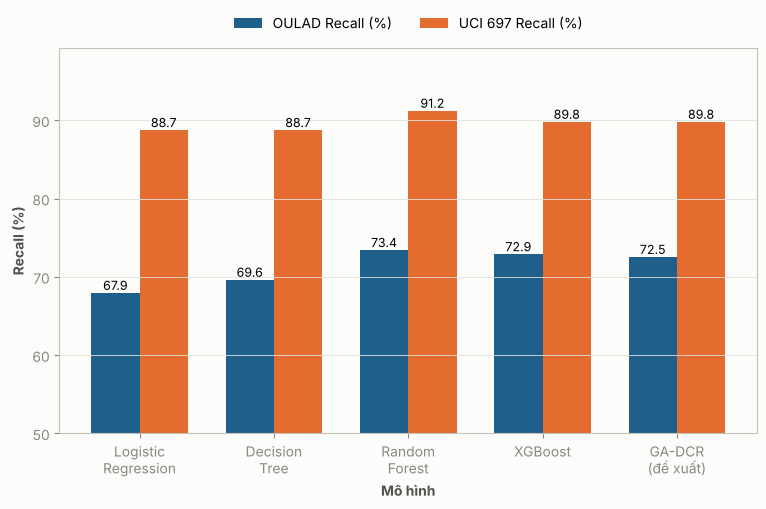

In [16]:
# Biểu đồ so sánh – 1 nhóm cột / mô hình, 2 cột: OULAD và UCI 697
DS_COLORS = {"OULAD": "#1f5f8b", "UCI 697": "#e46c2f"}
XLAB = ["Logistic\nRegression", "Decision\nTree", "Random\nForest", "XGBoost", "GA-DCR\n(đề xuất)"]
def bar_compare(metric, ylabel, fname):
    d = OP[OP.model.isin(MODELS)].pivot(index="model", columns="dataset", values=metric).loc[MODELS] * 100
    x, w = np.arange(len(MODELS)), 0.36
    fig, ax = plt.subplots(figsize=(9, 5))
    for k, ds in enumerate(["OULAD", "UCI 697"]):
        bars = ax.bar(x + (k - .5) * w, d[ds], w, color=DS_COLORS[ds], label=f"{ds} {ylabel} (%)")
        for b, v in zip(bars, d[ds]):
            ax.text(b.get_x() + b.get_width() / 2, v + .4, f"{v:.1f}", ha="center", fontsize=9)
    lo = max(0, np.floor(d.values.min() / 10) * 10 - 10)
    ax.set_ylim(lo, min(100, d.values.max() + 8)); ax.set_xticks(x, XLAB, fontsize=10)
    ax.set_ylabel(f"{ylabel} (%)", fontweight="bold"); ax.set_xlabel("Mô hình", fontweight="bold")
    ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(.5, 1.12)); ax.grid(axis="x", visible=False)
    ax.spines["top"].set_visible(True); ax.spines["right"].set_visible(True)
    save_show(fig, fname)

bar_compare("recall", "Recall", "06_recall_comparison.png")

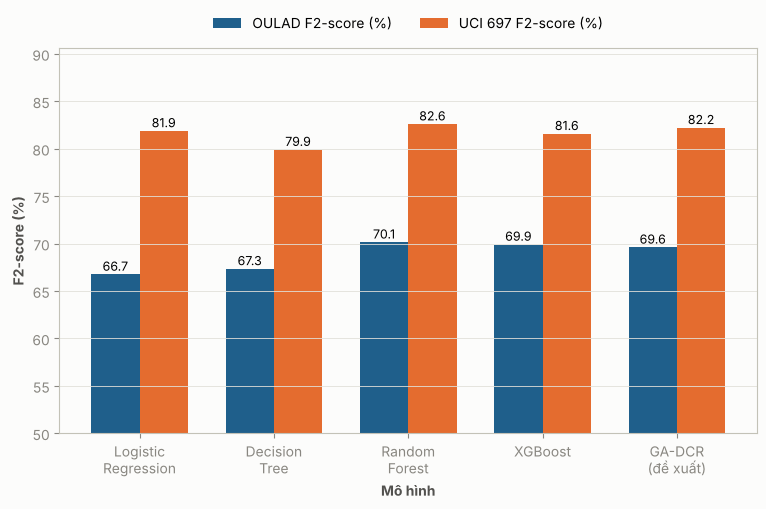

In [17]:
bar_compare("f2", "F2-score", "06_f2_comparison.png")

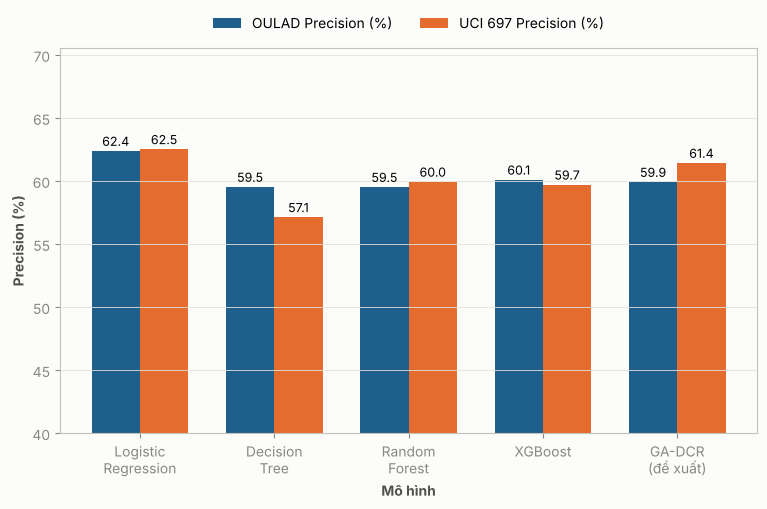

In [18]:
bar_compare("precision", "Precision", "06_precision_comparison.png")

### 6.1 Mức cảnh báo của GA-DCR (kết quả phân cụm động)
Nếu phân cụm có ý nghĩa thì **tỷ lệ SV nguy cơ thật phải tăng dần** từ Xanh → Vàng → Cam → Đỏ. *Recall cộng dồn* cho biết: nếu cố vấn xử lý từ mức Đỏ xuống thì bắt được bao nhiêu % SV nguy cơ.

,dataset,muc,n,ty_le_SV,ty_le_nguy_co_that,recall_cong_don,pct_SV_cong_don
0,OULAD,Đỏ,1239,0.087,0.872,0.179,0.087
1,OULAD,Cam,4192,0.294,0.505,0.530,0.381
2,OULAD,Vàng,8838,0.619,0.320,1.000,1.000
3,UCI 697,Đỏ,107,0.121,0.907,0.342,0.121
4,UCI 697,Vàng,355,0.401,0.439,0.891,0.522
5,UCI 697,Xanh,423,0.478,0.073,1.000,1.000


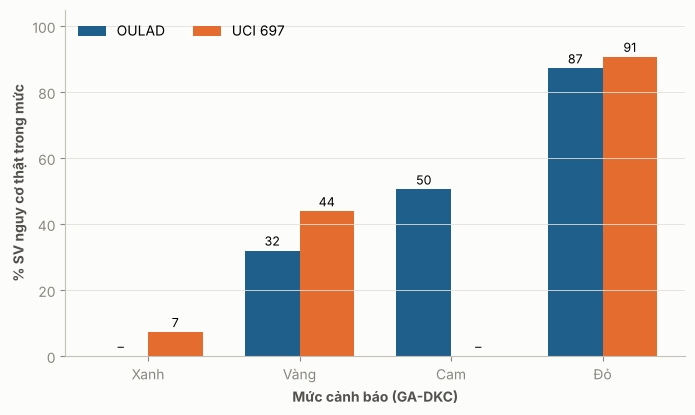

In [19]:
rows = []
for ds, g, X_te, yte in [("OULAD", gadcr_o, te_o, te_o.at_risk.values),
                         ("UCI 697", gadcr_u["Sau HK1"], U.loc[idx_te_u].astype({c: str for c in UCI_CAT}), U.loc[idx_te_u].at_risk.values)]:
    g.predict_proba(X_te); lv = pd.Series(g.last_level); cum_pos, cum_n = 0, 0
    for name in ["Đỏ", "Cam", "Vàng", "Xanh"]:
        m = (lv == name).values
        if not m.any(): continue
        cum_pos += yte[m].sum(); cum_n += m.sum()
        rows.append(dict(dataset=ds, muc=name, n=int(m.sum()), ty_le_SV=round(m.mean(), 3), ty_le_nguy_co_that=round(yte[m].mean(), 3),
                         recall_cong_don=round(cum_pos / yte.sum(), 3), pct_SV_cong_don=round(cum_n / len(yte), 3)))
lvtab = save_tab(pd.DataFrame(rows), "06_gadcr_levels.csv"); display(lvtab)

LV = ["Xanh", "Vàng", "Cam", "Đỏ"]; piv = lvtab.pivot(index="muc", columns="dataset", values="ty_le_nguy_co_that").reindex(LV) * 100
x, w = np.arange(len(LV)), 0.36
fig, ax = plt.subplots(figsize=(8, 4.5))
for k, ds in enumerate(["OULAD", "UCI 697"]):
    vals = piv[ds].values
    bars = ax.bar(x + (k - .5) * w, np.nan_to_num(vals), w, color=DS_COLORS[ds], label=ds)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, (0 if np.isnan(v) else v) + 1.5, "–" if np.isnan(v) else f"{v:.0f}", ha="center", fontsize=9)
ax.set_xticks(x, LV); ax.set_ylim(0, 105); ax.set_ylabel("% SV nguy cơ thật trong mức", fontweight="bold")
ax.set_xlabel("Mức cảnh báo (GA-DKC)", fontweight="bold"); ax.legend(ncol=2, loc="upper left"); ax.grid(axis="x", visible=False)
save_show(fig, "06_risk_by_warning_level.png")

---
## §7. Điểm mới so với bài báo tham khảo (Wang, 2025 – *Scientific Reports* 15:35122)
| Khía cạnh | Bài báo tham khảo (Hybrid-AIPM) | Đề tài này (GA-DCR) |
|---|---|---|
| Thuật toán cơ sở | DT, RF, **SVM, ANN** | **LR, DT, RF, XGBoost**: LR dễ giải thích cho cố vấn, XGBoost mạnh trên dữ liệu bảng |
| Cách kết hợp | Soft-voting / stacking các bộ phân loại | **Tăng cường bằng cụm rủi ro:** $s_k(x)$, $\rho(x)$, rồi hợp nhất $R=\alpha p+(1-\alpha)\rho$ |
| Phân cụm | Chỉ nhắc K-means trong phần tổng quan | **GA-DKC:** GA tối ưu *k* và trọng số đặc trưng; fitness = Silhouette + η² theo nhãn rủi ro; **chạy qua các mốc thời gian** (warm-start) |
| Đầu ra | Nhãn nhị phân | Xác suất, **mức cảnh báo Xanh/Vàng/Cam/Đỏ**, **quỹ đạo chuyển mức** |
| Chỉ số tối ưu | **Accuracy** (98,8%) | **Recall và F2** (ưu tiên không bỏ sót), Precision là **ràng buộc ổn định** |
| Ngưỡng quyết định | Mặc định 0,5 | $\tau^*=\arg\max F_2$ s.t. $P\ge\max(0{,}5;\bar y+0{,}15)$, % cảnh báo ≤ 50%, chọn trên OOF |
| Độ tin cậy | Trung bình 10-fold | Báo cáo **độ lệch chuẩn Precision giữa 5 fold** để kiểm tra Precision ổn định |
| Chia dữ liệu | Stratified 10-fold ngẫu nhiên | **OULAD theo thời gian** (2013 → 2014), **loại SV trùng giữa train và test**; UCI 80/20 phân tầng |
| Rò rỉ dữ liệu | Dùng G1 (UCI), dữ liệu cả khóa | Đặc trưng **cắt tại mốc t**; UCI lọc đặc trưng riêng từng mốc |
| Đặc trưng | Lọc tương quan Pearson > 0,85 và RF importance | **Khung 6 nhóm G1–G6 thống nhất cho 2 bộ**, thêm ★ đặc trưng mới; lọc Spearman > 0,85 |

**Ba đóng góp chính:**
1. **GA-DKC**: phân cụm động có hướng dẫn rủi ro, tự sinh mức cảnh báo theo thời gian.
2. Công thức hợp nhất **cụm–xác suất** $R(x)$, kèm **quy tắc chọn ngưỡng hướng Recall có ràng buộc Precision**.
3. Quy trình đánh giá **chống rò rỉ, theo thời gian** trên 2 bộ dữ liệu khác cấu trúc.

In [20]:
B = OP[~OP.model.str.startswith("(tham")]
best_r = B.sort_values("f2", ascending=False).groupby("dataset").head(1).set_index("dataset")
gad = B[B.model == "GA-DCR (đề xuất)"].set_index("dataset"); allpos = OP[OP.model.str.startswith("(tham")].set_index("dataset")
summary = pd.DataFrame({"Baseline tốt nhất (F2)": best_r.model, "Recall baseline": best_r.recall, "F2 baseline": best_r.f2,
                        "P baseline": best_r.precision, "Recall GA-DCR": gad.recall, "F2 GA-DCR": gad.f2, "P GA-DCR": gad.precision,
                        "SD P GA-DCR": gad.prec_fold_sd, "ΔRecall": gad.recall - best_r.recall, "ΔF2": gad.f2 - best_r.f2,
                        "F2 'cảnh báo tất cả'": allpos.f2})
save_tab(summary.round(3).reset_index(), "07_summary.csv"); summary.round(3)

,Baseline tốt nhất (F2),Recall baseline,F2 baseline,P baseline,Recall GA-DCR,F2 GA-DCR,P GA-DCR,SD P GA-DCR,ΔRecall,ΔF2,F2 'cảnh báo tất cả'
dataset,,,,,,,,,,,
OULAD,RandomForest,0.734,0.701,0.595,0.725,0.696,0.599,0.006,-0.009,-0.005,0.785
UCI 697,RandomForest,0.912,0.826,0.600,0.898,0.822,0.614,0.019,-0.014,-0.004,0.703


**Cách đọc cột "F2 'cảnh báo tất cả'":** khi tỷ lệ nguy cơ cao (OULAD 42%), chiến lược suy biến "cảnh báo mọi SV" có Recall = 1 nên F2 rất cao, nhưng Precision chỉ bằng tỷ lệ nguy cơ và phải gặp 100% SV. Chiến lược này **vi phạm cả hai ràng buộc** ($P \ge P_{min}$, % cảnh báo ≤ 50%), nên không thể so F2 của nó trực tiếp với các mô hình. Phép so sánh hợp lệ là **giữa các mô hình cùng thỏa ràng buộc**. Ở đó, một mô hình tốt hơn là mô hình đạt **Recall cao hơn với cùng mức Precision và cùng % SV phải gặp**.

### Kết luận tuần 2 và việc tiếp theo
- **Chỉ số:** Recall và F2 là thước đo chính. Precision được giữ **≥ P_min và ổn định** (SD nhỏ giữa các fold), và số SV bị cảnh báo được giới hạn để cố vấn xử lý được.
- **Đặc trưng:** hai bộ dữ liệu dùng chung khung 6 nhóm G1–G6. Số đặc trưng chốt lại nằm ở bảng §3.
- **Phân cụm động GA-DKC:** tạo ra các mức cảnh báo có tỷ lệ nguy cơ thật tăng dần từ Xanh đến Đỏ (§6.1).
- **GA-DCR** được đặt cạnh 4 baseline với **cùng quy tắc chọn ngưỡng**. Theo yêu cầu tuần 2, mô hình **chưa được tinh chỉnh để thắng**.
- **Hướng cải thiện Recall và F2 từ tuần 3:**
  1. Hàm mất mát nhạy chi phí cho FN (focal loss hoặc trọng số FN/FP theo chi phí tư vấn);
  2. Đặc trưng **quỹ đạo mức cảnh báo** qua các mốc;
  3. Tối ưu siêu tham số theo F2 có ràng buộc (Optuna);
  4. Hiệu chỉnh xác suất (calibration) để Precision ổn định khi tỷ lệ nguy cơ thay đổi giữa các khóa;
  5. Kiểm định McNemar cho chênh lệch Recall so với baseline.